In [4]:
from bleak import BleakScanner
import asyncio

TARGET_NAME = "P715 54922"

found = await BleakScanner.discover(timeout=10, return_adv=True)

p715_matches = []

for address, (device, adv) in found.items():
    # 有些 Windows 藍牙掃描會讓 device.name 顯示 None，
    # 因此同時檢查 advertisement 的名稱。
    name = adv.local_name or device.name or ""

    print(f"名稱={name!r} | 位址={address} | 訊號={adv.rssi}")

    # 只選主要 P715；排除右踏板名稱 P715 xxxxx R
    if TARGET_NAME in name and not name.strip().endswith(" R"):
        p715_matches.append(device)

if len(p715_matches) == 1:
    device = p715_matches[0]
    print(f"\n已自動選擇主踏板：{device}")

elif len(p715_matches) == 0:
    raise RuntimeError(
        "沒有找到 P715 54922。請關閉 Magene Utility／Chrome，"
        "踩幾圈喚醒踏板後再執行一次。"
    )

else:
    raise RuntimeError(f"找到多個 P715 54922：{p715_matches}")

名稱='' | 位址=77:36:62:65:F8:5C | 訊號=-91
名稱='' | 位址=59:99:AA:0F:14:C7 | 訊號=-92
名稱='57_32736' | 位址=EC:40:14:CD:6F:8F | 訊號=-53
名稱='P715 64059 R' | 位址=D8:05:0A:4B:30:68 | 訊號=-61
名稱='' | 位址=52:A4:00:2E:AF:B3 | 訊號=-89
名稱='' | 位址=14:75:5C:25:E8:5E | 訊號=-80
名稱='' | 位址=E2:70:EA:45:9D:22 | 訊號=-79
名稱='' | 位址=1D:5B:48:14:10:64 | 訊號=-87
名稱='P715 54922' | 位址=FD:25:17:79:3B:6C | 訊號=-66
名稱='' | 位址=7B:3A:19:08:CB:CE | 訊號=-92
名稱='' | 位址=31:7A:D2:18:CD:9E | 訊號=-68
名稱='' | 位址=5B:A4:FA:2F:98:FC | 訊號=-88
名稱='' | 位址=32:DE:D0:46:FE:DE | 訊號=-79
名稱='' | 位址=32:26:3C:62:FA:43 | 訊號=-85
名稱='' | 位址=26:6A:0E:8E:85:22 | 訊號=-85
名稱='' | 位址=7E:77:C7:0B:90:13 | 訊號=-85
名稱='' | 位址=69:9C:32:A9:B2:BB | 訊號=-61
名稱='' | 位址=67:DB:FB:FC:6B:2B | 訊號=-88
名稱='' | 位址=71:5A:EF:C0:47:5C | 訊號=-89
名稱='' | 位址=6F:1D:46:39:C4:C6 | 訊號=-95
名稱='' | 位址=EB:67:78:19:9C:C3 | 訊號=-58
名稱='' | 位址=FC:B4:B0:A3:29:98 | 訊號=-37
名稱='' | 位址=03:F6:B2:EF:DA:79 | 訊號=-86
名稱='' | 位址=32:8B:AD:39:C1:96 | 訊號=-78
名稱='' | 位址=54:11:1D:97:D1:A1 | 訊號=-93
名稱='' | 位址=51:5E:2D:

In [5]:
from bleak import BleakClient
from IPython.display import clear_output
import pandas as pd
import time

CYCLING_POWER_MEASUREMENT = "00002a63-0000-1000-8000-00805f9b34fb"

print(f"Selected main pedal: {device}")


Selected main pedal: FD:25:17:79:3B:6C: P715 54922


In [6]:
records = []
last_crank = None

def decode_p715(data):
    global last_crank
    d = bytearray(data)
    flags = int.from_bytes(d[0:2], "little")
    power = int.from_bytes(d[2:4], "little", signed=True)
    position = 4
    balance = None
    balance_reference = None
    cadence = None
    if flags & 0x0001:
        balance = d[position] / 2
        balance_reference = "left" if flags & 0x0002 else "unknown"
        position += 1
    if flags & 0x0004:
        position += 2
    if flags & 0x0010:
        position += 6
    if flags & 0x0020:
        crank_revs = int.from_bytes(d[position:position+2], "little")
        crank_time = int.from_bytes(d[position+2:position+4], "little")
        if last_crank:
            rev_diff = (crank_revs - last_crank["revs"]) % 65536
            time_diff = (crank_time - last_crank["time"]) % 65536
            if rev_diff > 0 and time_diff > 0:
                cadence = rev_diff * 60 * 1024 / time_diff
        last_crank = {"revs": crank_revs, "time": crank_time}
    left_power = None
    right_power = None
    if balance is not None and balance_reference == "left":
        left_power = power * balance / 100
        right_power = power - left_power
    return {
        "timestamp": time.time(),
        "power_w": power,
        "cadence_rpm": cadence,
        "balance_percent": balance,
        "balance_reference": balance_reference,
        "left_power_w": left_power,
        "right_power_w": right_power,
        "raw_hex": d.hex(" ")
    }

def on_power_data(sender, data):
    result = decode_p715(data)
    records.append(result)
    clear_output(wait=True)
    print("P715 live data")
    print(f"Total power: {result['power_w']} W")
    if result["left_power_w"] is not None:
        print(f"Estimated left/right power: L {result['left_power_w']:.1f} W | R {result['right_power_w']:.1f} W")
        print(f"Balance: L {result['balance_percent']:.1f}% | R {100 - result['balance_percent']:.1f}%")
    else:
        print("Balance: no interpretable left/right data in this packet")
    print(f"Cadence: {result['cadence_rpm']:.1f} rpm" if result["cadence_rpm"] is not None else "Cadence: calculating")

async with BleakClient(device) as client:
    try:
        print("Connected. Collecting for 60 seconds.")
        await client.start_notify(CYCLING_POWER_MEASUREMENT, on_power_data)
        await asyncio.sleep(60)
    except KeyboardInterrupt:
        print("Collection stopped manually.")
    finally:
        if client.is_connected:
            await client.stop_notify(CYCLING_POWER_MEASUREMENT)

df = pd.DataFrame(records)
df.to_csv("p715_data.csv", index=False)
print("\nCollection complete")
print(f"Average total power: {df['power_w'].mean():.1f} W")
print(f"Average cadence: {df['cadence_rpm'].mean():.1f} rpm")
if df["left_power_w"].notna().any():
    print(f"Average estimated left power: {df['left_power_w'].mean():.1f} W")
    print(f"Average estimated right power: {df['right_power_w'].mean():.1f} W")
    print(f"Average left balance: {df['balance_percent'].mean():.1f}%")
    print(f"Average right balance: {100 - df['balance_percent'].mean():.1f}%")
df.tail()


P715 live data
Total power: 19 W
Estimated left/right power: L 0.0 W | R 19.0 W
Balance: L 0.0% | R 100.0%
Cadence: calculating

Collection complete
Average total power: 53.8 W
Average cadence: 88.9 rpm
Average estimated left power: 20.8 W
Average estimated right power: 33.0 W
Average left balance: 36.5%
Average right balance: 63.5%


,timestamp,power_w,cadence_rpm,balance_percent,balance_reference,left_power_w,right_power_w,raw_hex
55,1.791550e+09,36,90.954848,36.0,left,12.96,23.04,2f 60 24 00 48 00 e0 64 49 f5 ff 28 58 16 1a
56,1.791550e+09,41,91.976048,22.0,left,9.02,31.98,2f 60 29 00 2c 88 e0 65 49 91 02 24 6e 0e 1c
57,1.791550e+09,19,81.810919,0.0,left,0.00,19.00,2f 60 13 00 00 2d e1 67 49 6f 08 00 6a 00 20
58,1.791550e+09,19,NaN,0.0,left,0.00,19.00,2f 60 13 00 00 2d e1 67 49 6f 08 00 6a 00 20
59,1.791550e+09,19,NaN,0.0,left,0.00,19.00,2f 60 13 00 00 2d e1 67 49 6f 08 00 6a 00 20


In [7]:
import pandas as pd
from IPython.display import display

df = pd.read_csv("p715_data.csv")

# 排除停止踩踏或平衡資料無效的封包，用於看左右腳比例
active = df[(df["power_w"] > 0) & (df["balance_percent"] > 0)].copy()

summary = pd.DataFrame({
    "項目": [
        "測量時間（秒）",
        "資料筆數",
        "平均總功率（W）",
        "最高總功率（W）",
        "平均踏頻（rpm）",
        "最高踏頻（rpm）",
        "左腳平衡（%）",
        "右腳平衡（%）",
        "左腳估計功率（W）",
        "右腳估計功率（W）",
    ],
    "結果": [
        round(df["timestamp"].iloc[-1] - df["timestamp"].iloc[0], 1),
        len(df),
        round(df["power_w"].mean(), 1),
        round(df["power_w"].max(), 1),
        round(df["cadence_rpm"].mean(), 1),
        round(df["cadence_rpm"].max(), 1),
        round(active["balance_percent"].mean(), 1),
        round(100 - active["balance_percent"].mean(), 1),
        round(active["left_power_w"].mean(), 1),
        round(active["right_power_w"].mean(), 1),
    ],
})

display(summary)

# 每一列是一個即時藍牙封包；不顯示 raw_hex
view = df.copy()
view["經過秒數"] = (view["timestamp"] - view["timestamp"].iloc[0]).round(1)

view = view[
    ["經過秒數", "power_w", "cadence_rpm",
     "balance_percent", "left_power_w", "right_power_w"]
].rename(columns={
    "power_w": "總功率_W",
    "cadence_rpm": "踏頻_rpm",
    "balance_percent": "左腳比例_%",
    "left_power_w": "左腳估計功率_W",
    "right_power_w": "右腳估計功率_W",
})

display(view.head(20))

,項目,結果
0,測量時間（秒）,59.0
1,資料筆數,60.0
2,平均總功率（W）,53.8
3,最高總功率（W）,130.0
4,平均踏頻（rpm）,88.9
5,最高踏頻（rpm）,96.0
6,左腳平衡（%）,38.9
7,右腳平衡（%）,61.1
8,左腳估計功率（W）,22.7
9,右腳估計功率（W）,34.5


,經過秒數,總功率_W,踏頻_rpm,左腳比例_%,左腳估計功率_W,右腳估計功率_W
0,0.0,0,NaN,50.0,0.00,0.00
1,1.1,86,35.008547,50.0,43.00,43.00
2,2.0,130,59.020173,45.0,58.50,71.50
3,3.0,105,69.977221,36.0,37.80,67.20
4,4.0,95,74.024096,29.0,27.55,67.45
5,5.0,60,76.039604,40.0,24.00,36.00
6,6.0,50,78.971722,56.0,28.00,22.00
7,7.1,67,80.000000,37.0,24.79,42.21
8,8.1,52,80.000000,38.0,19.76,32.24
9,9.1,62,81.001978,56.0,34.72,27.28


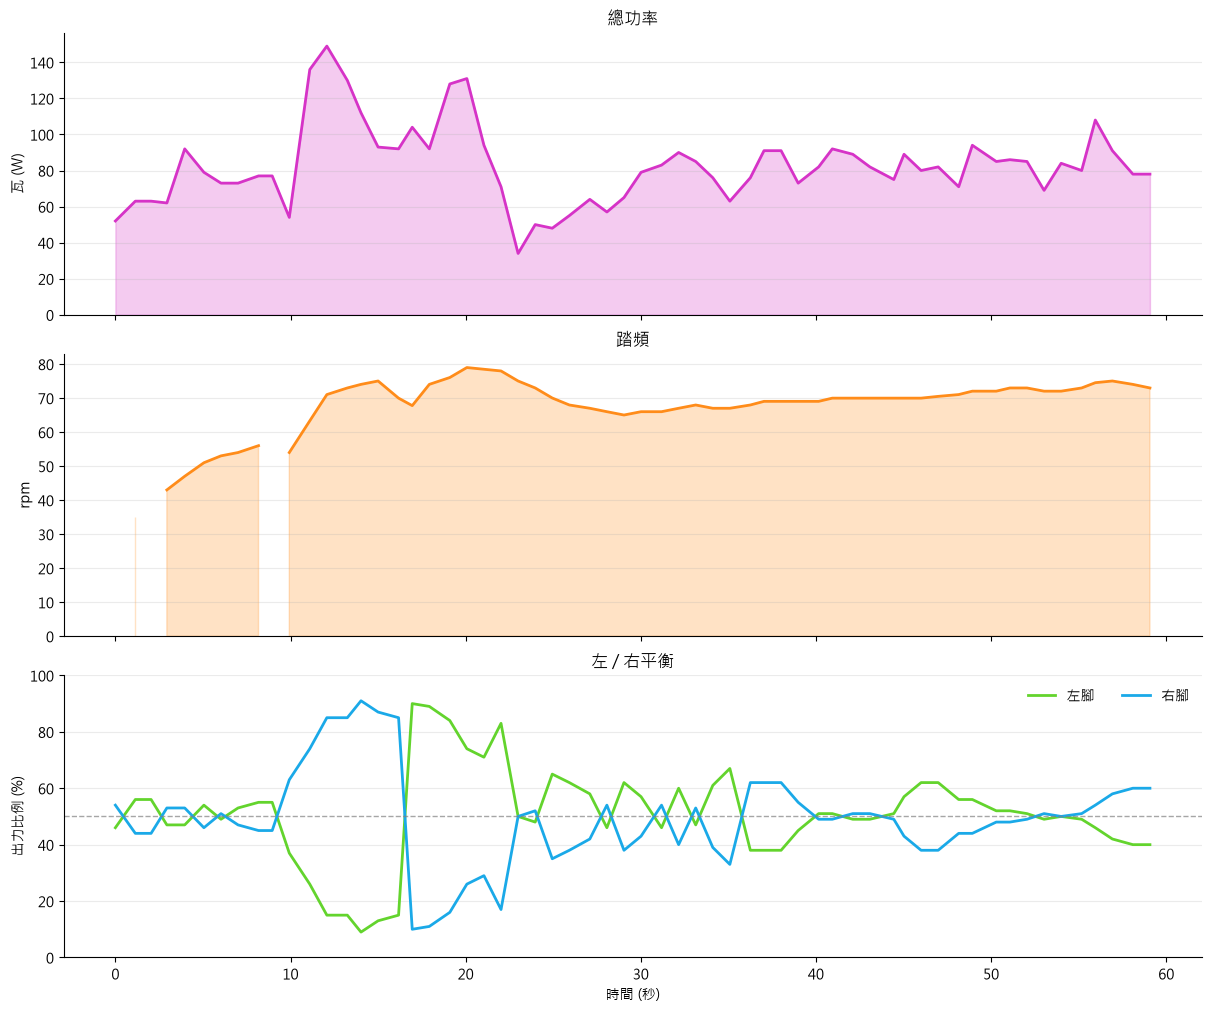

平均功率: 82.6 W | 平均踏頻: 67.8 rpm | 左右平衡: 50.7% / 49.3%


In [9]:
# Connect-like overview: re-run this cell after each new p715_data.csv collection.
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = [
    "Microsoft JhengHei", "Noto Sans CJK TC", "Arial Unicode MS", "DejaVu Sans"
]
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("p715_data.csv").copy()
if df.empty:
    raise ValueError("p715_data.csv is empty. Please collect a ride first.")

df["elapsed_s"] = df["timestamp"] - df["timestamp"].iloc[0]
df = df.sort_values("elapsed_s")

# A balance of 0 is a stop/no-valid-balance packet, so leave a gap instead of plotting it as 0%.
df["left_balance_pct"] = df["balance_percent"].where(df["balance_percent"] > 0)
df["right_balance_pct"] = 100 - df["left_balance_pct"]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, layout="constrained")

def connect_style(ax):
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

# 1. Total power
axes[0].plot(df["elapsed_s"], df["power_w"], color="#d633c7", linewidth=2)
axes[0].fill_between(df["elapsed_s"], df["power_w"], color="#d633c7", alpha=0.25)
axes[0].set_title("\u7e3d\u529f\u7387")
axes[0].set_ylabel("\u74e6 (W)")
axes[0].set_ylim(bottom=0)
connect_style(axes[0])

# 2. Cadence
axes[1].plot(df["elapsed_s"], df["cadence_rpm"], color="#ff8c1a", linewidth=2)
axes[1].fill_between(df["elapsed_s"], df["cadence_rpm"], color="#ff8c1a", alpha=0.25)
axes[1].set_title("\u8e0f\u983b")
axes[1].set_ylabel("rpm")
axes[1].set_ylim(bottom=0)
connect_style(axes[1])

# 3. Left/right balance
axes[2].plot(
    df["elapsed_s"], df["left_balance_pct"],
    color="#63d42d", linewidth=2, label="\u5de6\u8173"
)
axes[2].plot(
    df["elapsed_s"], df["right_balance_pct"],
    color="#1aa9e8", linewidth=2, label="\u53f3\u8173"
)
axes[2].axhline(50, color="gray", linewidth=1, linestyle="--", alpha=0.7)
axes[2].set_title("\u5de6 / \u53f3\u5e73\u8861")
axes[2].set_xlabel("\u6642\u9593 (\u79d2)")
axes[2].set_ylabel("\u51fa\u529b\u6bd4\u4f8b (%)")
axes[2].set_ylim(0, 100)
axes[2].legend(frameon=False, ncols=2)
connect_style(axes[2])

plt.show()

active = df[(df["power_w"] > 0) & (df["left_balance_pct"].notna())]
print(
    f"\u5e73\u5747\u529f\u7387: {df['power_w'].mean():.1f} W | "
    f"\u5e73\u5747\u8e0f\u983b: {df['cadence_rpm'].mean():.1f} rpm | "
    f"\u5de6\u53f3\u5e73\u8861: {active['left_balance_pct'].mean():.1f}% / "
    f"{active['right_balance_pct'].mean():.1f}%"
)